# IPAB Istat: l'indice dei prezzi delle abitazioni, 2016-2024

**Domanda del progetto:** il rincaro percepito dei prezzi delle case trova riscontro nei dati ufficiali?

**Fonte:** Istat, *Indice dei prezzi delle abitazioni (IPAB)*, dataset "Trimestrali dal 2010 al 2024 (base 2015)". Dati scaricati il 10 ottobre 2026.

**Cos'è il dato:** un *numero indice* con base 2015 = 100. Un valore di 113,5 significa "prezzi più alti del 13,5% rispetto al livello del 2015". Non sono euro al metro quadro e non riguarda gli affitti.

**Cosa contiene il file:** 5 territori (Italia, Nord-ovest, Nord-est, Centro, Mezzogiorno) × 3 voci (tutte le voci, abitazioni nuove, abitazioni esistenti) × 60 trimestri (2010-Q1 → 2024-Q4).

**Struttura del notebook**
1. Librerie
2. Caricamento dei dati
3. Primo sguardo ai dati
4. Pulizia e preparazione
5. Verifiche di qualità
6. Trasformare i trimestri in date
7. Analisi: la serie nazionale
8. Rappresentazione grafica
9. Note e limiti

## 1. Librerie
- **pandas** (`pd`): lavora con le tabelle. Una tabella in memoria si chiama *DataFrame*.
- **matplotlib.pyplot** (`plt`): disegna i grafici.

In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

## 2. Caricamento dei dati
`pd.read_csv()` legge il file CSV e lo trasforma in un DataFrame, che salviamo nella variabile `ipab`.

Il file originale in `data/Raw/Istat` **non viene mai modificato**: ogni cambiamento avviene in memoria, su variabili nuove. Il percorso è *relativo* (parte dalla cartella `notebooks`), così il notebook non dipende dal computer su cui gira.

In [3]:
ipab = pd.read_csv("../data/Raw/Istat/ipab_trimestrale_base2015.csv")

## 3. Primo sguardo ai dati
Prima di calcolare qualsiasi cosa si guarda com'è fatta la tabella, con tre comandi:
- `.shape`: un *attributo* (senza parentesi) con righe e colonne.
- `.head()`: un *metodo* (con parentesi) che mostra le prime 5 righe.
- `.info()`: un metodo che elenca le colonne, il tipo di dato (`dtype`) e quante celle non sono vuote.

In [4]:
ipab.shape

(900, 14)

In [5]:
ipab.head()

,FREQ,Frequenza,REF_AREA,Territorio,DATA_TYPE,Indicatore,MEASURE,Misura,PURCHASES_DWELLINGS,Abitazioni compravendute,TIME_PERIOD,Osservazione,OBS_STATUS,"'Stato dell""'osservazione'"
0,Q,Trimestrale,IT,Italia,59,Indice dei prezzi delle abitazioni (base 2015=...,4,Numeri indici,ALL,H1 - tutte le voci,2010-Q1,116.8,NaN,NaN
1,Q,Trimestrale,IT,Italia,59,Indice dei prezzi delle abitazioni (base 2015=...,4,Numeri indici,ALL,H1 - tutte le voci,2010-Q2,117.9,NaN,NaN
2,Q,Trimestrale,IT,Italia,59,Indice dei prezzi delle abitazioni (base 2015=...,4,Numeri indici,ALL,H1 - tutte le voci,2010-Q3,118.8,NaN,NaN
3,Q,Trimestrale,IT,Italia,59,Indice dei prezzi delle abitazioni (base 2015=...,4,Numeri indici,ALL,H1 - tutte le voci,2010-Q4,118.9,NaN,NaN
4,Q,Trimestrale,IT,Italia,59,Indice dei prezzi delle abitazioni (base 2015=...,4,Numeri indici,ALL,H1 - tutte le voci,2011-Q1,118.3,NaN,NaN


In [6]:
ipab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   FREQ                        900 non-null    object 
 1   Frequenza                   900 non-null    object 
 2   REF_AREA                    900 non-null    object 
 3   Territorio                  900 non-null    object 
 4   DATA_TYPE                   900 non-null    int64  
 5   Indicatore                  900 non-null    object 
 6   MEASURE                     900 non-null    int64  
 7   Misura                      900 non-null    object 
 8   PURCHASES_DWELLINGS         900 non-null    object 
 9   Abitazioni compravendute    900 non-null    object 
 10  TIME_PERIOD                 900 non-null    object 
 11  Osservazione                900 non-null    float64
 12  OBS_STATUS                  15 non-null     object 
 13  'Stato dell"'osservazione'  15 non-

**Cosa osserviamo**
- **900 righe** = 60 trimestri × 15 combinazioni (5 territori × 3 voci), **14 colonne**.
- Il formato è *lungo*: ogni riga è una combinazione di territorio, voce e trimestre.
- Molte colonne non servono: sei sono uguali in tutte le righe (`FREQ`, `Frequenza`, `DATA_TYPE`, `MEASURE`, `Misura`, `Indicatore`) e due sono solo il codice di un'altra colonna (`REF_AREA`, `PURCHASES_DWELLINGS`).
- `Osservazione` è il valore dell'indice (`float64`, numero decimale). Nonostante il nome, `Abitazioni compravendute` contiene la voce (H1, H11, H12).
- `TIME_PERIOD` è `object`, cioè **testo**: per Python `2010-Q1` non è ancora una data.
- Le ultime due colonne hanno solo 15 valori: segnalano righe con uno stato particolare. L'ultima ha un nome rovinato dall'esportazione.

## 4. Pulizia e preparazione
Teniamo solo ciò che serve, con nomi chiari, e limitiamo il periodo. Si lavora sempre su variabili nuove, senza toccare `ipab`.

### 4.1 Selezione delle colonne
Con le doppie parentesi quadre si sceglie l'elenco delle colonne da tenere: `tabella[["a", "b"]]`.

In [7]:
ipab_pulito = ipab[["Territorio","Abitazioni compravendute","TIME_PERIOD","Osservazione","OBS_STATUS"]]

In [8]:
ipab_pulito.head()

,Territorio,Abitazioni compravendute,TIME_PERIOD,Osservazione,OBS_STATUS
0,Italia,H1 - tutte le voci,2010-Q1,116.8,NaN
1,Italia,H1 - tutte le voci,2010-Q2,117.9,NaN
2,Italia,H1 - tutte le voci,2010-Q3,118.8,NaN
3,Italia,H1 - tutte le voci,2010-Q4,118.9,NaN
4,Italia,H1 - tutte le voci,2011-Q1,118.3,NaN


### 4.2 Rinomina delle colonne
`.rename(columns={...})` accetta un *dizionario*, cioè coppie `"nome vecchio": "nome nuovo"`. Restituisce una tabella nuova, quindi il risultato va assegnato a una variabile. I nuovi nomi sono in minuscolo e descrivono il contenuto.

In [9]:
ipab_pulito = ipab_pulito.rename(columns={"Territorio": "territorio","Abitazioni compravendute": "tipo_abitazione","TIME_PERIOD": "trimestre" ,"Osservazione": "indice" ,"OBS_STATUS":"stato_dato"})

In [10]:
ipab_pulito.head()

,territorio,tipo_abitazione,trimestre,indice,stato_dato
0,Italia,H1 - tutte le voci,2010-Q1,116.8,NaN
1,Italia,H1 - tutte le voci,2010-Q2,117.9,NaN
2,Italia,H1 - tutte le voci,2010-Q3,118.8,NaN
3,Italia,H1 - tutte le voci,2010-Q4,118.9,NaN
4,Italia,H1 - tutte le voci,2011-Q1,118.3,NaN


### 4.3 Filtro sul periodo (dal 2016)
Il progetto copre gli ultimi anni, dal 2016, lo stesso periodo dei dati OMI. La condizione `ipab_pulito["trimestre"] >= "2016-Q1"` produce una *maschera booleana* (vero o falso per ogni riga) e pandas tiene solo le righe vere. Il confronto funziona anche sul testo, perché il formato anno-trimestre si ordina correttamente in ordine alfabetico.

`.copy()` crea una copia indipendente, ed evita l'avviso `SettingWithCopyWarning` quando poi aggiungiamo colonne.

**Controllo:** attese 540 righe (36 trimestri × 15 combinazioni), da `2016-Q1` a `2024-Q4`.

In [11]:
ipab_2016 = ipab_pulito[ipab_pulito["trimestre"] >= "2016-Q1"].copy()

In [12]:
ipab_2016.shape

(540, 5)

In [13]:
ipab_2016["trimestre"].min()

'2016-Q1'

In [14]:
ipab_2016["trimestre"].max()

'2024-Q4'

## 5. Verifiche di qualità
Prima di fidarsi dei dati si controlla che siano completi e coerenti. Ogni verifica ha un risultato atteso:

| Verifica | Come | Atteso |
|---|---|---|
| Valori mancanti | `isna().sum()` conta le celle vuote di `indice` | 0 |
| Righe doppie | `duplicated([...]).sum()` conta le combinazioni territorio-voce-trimestre ripetute | 0 |
| Righe per territorio | `value_counts()` | 108 ciascuno (36 trimestri × 3 voci) |
| Stato del dato | `value_counts()` su `stato_dato` | 15 righe con `r` |
| Righe per voce | `value_counts()` | 180 ciascuna (36 trimestri × 5 territori) |

In [15]:
ipab_2016["indice"].isna().sum()

np.int64(0)

In [16]:
ipab_2016.duplicated(["territorio", "tipo_abitazione", "trimestre"]).sum()

np.int64(0)

In [17]:
ipab_2016["territorio"].value_counts()

territorio
Italia         108
Nord-ovest     108
Nord-est       108
Centro         108
Mezzogiorno    108
Name: count, dtype: int64

In [18]:
ipab_2016["stato_dato"].value_counts()

stato_dato
r    15
Name: count, dtype: int64

In [19]:
ipab_2016["tipo_abitazione"].value_counts()

tipo_abitazione
H1 - tutte le voci            180
H11 - abitazioni nuove        180
H12 - abitazioni esistenti    180
Name: count, dtype: int64

**Esito:** dati completi, senza duplicati e con tutti i trimestri per ogni territorio.

**Stato `r`:** le 15 righe con questo stato sono tutte del 2019-Q2 (una per ogni combinazione di territorio e voce). Il file non spiega il codice e le righe restano com'è.

## 6. Trasformare i trimestri in date
`trimestre` è testo (`2016-Q1`): per ordinare nel tempo e disegnare un asse servono vere date (tipo `datetime`).
- `pd.PeriodIndex(colonna, freq="Q")` riconosce il testo come trimestre. `freq` è un *argomento con nome*, e `"Q"` indica la frequenza trimestrale (anno solare).
- `.to_timestamp()` lo converte nel **primo giorno** del trimestre (`2016-Q1` diventa 1 gennaio 2016).
- Una nuova colonna si crea assegnando a `tabella["nome_nuovo"]`.

**Convenzione importante:** l'indice descrive **l'intero trimestre**, non il primo o l'ultimo giorno. La data a inizio trimestre è solo un'etichetta per l'asse del grafico. Per spostarla a fine trimestre esiste `to_timestamp(how="end")`.

In [20]:
ipab_2016["data"] = pd.PeriodIndex(ipab_2016["trimestre"], freq="Q").to_timestamp()

In [21]:
ipab_2016[["trimestre","data"]].head()

,trimestre,data
24,2016-Q1,2016-01-01
25,2016-Q2,2016-04-01
26,2016-Q3,2016-07-01
27,2016-Q4,2016-10-01
28,2017-Q1,2017-01-01


In [22]:
ipab_2016["data"].dtype

dtype('<M8[ns]')

Il tipo `<M8[ns]` mostrato da `.dtype` è `datetime64`: ora la colonna `data` è una data vera.

In [23]:
ipab_2016.head()

,territorio,tipo_abitazione,trimestre,indice,stato_dato,data
24,Italia,H1 - tutte le voci,2016-Q1,99.8,NaN,2016-01-01
25,Italia,H1 - tutte le voci,2016-Q2,100.5,NaN,2016-04-01
26,Italia,H1 - tutte le voci,2016-Q3,100.7,NaN,2016-07-01
27,Italia,H1 - tutte le voci,2016-Q4,100.0,NaN,2016-10-01
28,Italia,H1 - tutte le voci,2017-Q1,99.1,NaN,2017-01-01


## 7. Analisi: la serie nazionale
Partiamo dalla serie più semplice: **Italia, tutte le voci**. Due condizioni si uniscono con `&` (e), ciascuna tra parentesi tonde. Dentro una condizione `==` **confronta**, mentre `=` **assegna**.

Risultato atteso: 36 righe (36 trimestri) e 6 colonne.

In [24]:
italia_totale = ipab_2016[(ipab_2016["territorio"] == "Italia") & (ipab_2016["tipo_abitazione"] == "H1 - tutte le voci")].copy()

In [25]:
italia_totale.shape

(36, 6)

## 8. Rappresentazione grafica
`plt.plot(x, y)` disegna una linea: sull'asse orizzontale le date, su quello verticale l'indice. `plt.title()` e `plt.ylabel()` aggiungono titolo ed etichetta, `plt.axhline(100)` traccia la linea di riferimento a 100 (il livello del 2015) e `plt.show()` mostra il grafico.

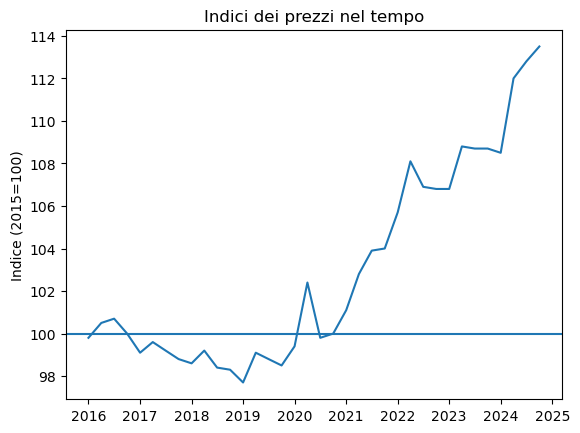

In [26]:
plt.plot(italia_totale["data"], italia_totale["indice"])
plt.title("Indici dei prezzi nel tempo")
plt.ylabel("Indice (2015=100)")
plt.axhline(100)
plt.show()

**Cosa osserviamo (indice nazionale, tutte le voci)**
- **2016-2019:** lieve discesa, fino al minimo di **97,7** nel 2019-Q1.
- **2020:** un picco isolato nel 2020-Q2 (102,4), che rientra subito (99,8 nel trimestre dopo).
- **Dal 2021:** salita decisa, che si ferma dal 2022-Q2 al 2024-Q1, con l'indice tra 106,8 e 108,8.
- **2024:** nuova accelerazione, con 112,0 nel 2024-Q2 e **113,5** nel 2024-Q4.
- Da inizio 2016 (99,8) a fine 2024 (113,5) l'aumento è di circa il **+13,7%**, in termini *nominali*, cioè senza correggere per l'inflazione.

## 9. Note e limiti
- **È un indice, non un prezzo:** misura le variazioni rispetto al 2015, non i €/m². Non include gli affitti.
- **Dato già elaborato da Istat:** non sono le transazioni grezze.
- **Valori nominali:** non corretti per l'inflazione.
- **Territori:** solo 4 aree. Il "Mezzogiorno" comprende Sud e Isole insieme.
- **Periodo:** la serie finisce al 2024-Q4, mentre i dati OMI arrivano al 2025.
- **Stato `r` nel 2019-Q2:** 15 valori con un codice di stato che il file non spiega, tenuti senza modifiche.
- **Date dei trimestri:** l'indice riguarda l'intero trimestre. Nel grafico è collocato a inizio trimestre.